# Faster MACE Inference with cuEquivariance and ASE

In this tutorial we demonstrate how to accelerate inference of trained Franken models with MACE backbones using **cuEquivariance** native CUDA kernels.

Franken uses standard `e3nn` with forward-mode feature derivatives during training. Once a model is fitted, the backbone can be seamlessly converted to use `cuEquivariance` for inference through `FrankenCalculator(..., use_cueq=True)` without altering the fitted random-feature coefficients, energy shifts, or input scaling.

We will:
1. Load a fitted Franken MACE checkpoint with `e3nn` and `cuEquivariance` backends.
2. Verify numerical consistency between both backends on energies and forces.
3. Benchmark throughput across system sizes (from 8 to 1,000 atoms) using bulk Silicon.
4. Compare Molecular Dynamics (MD) execution time in an ASE NVT simulation.

> **Prerequisites:** 
> - A CUDA GPU (Turing, Ampere, Ada Lovelace, or newer; Volta is not supported by cuEquivariance 0.10 wheels).
> - A matching cuEquivariance extra installed, e.g. `pip install "franken[cueq-cu12]"` or `pip install "franken[cueq-cu13]"`.
> - A trained Franken MACE checkpoint (`best_ckpt.pt`), e.g. from the installation check command:
>   ```bash
>   franken.autotune --dataset-name test --backbone mace --mace.path-or-id mace_mp/small \
>       --rf gaussian --gaussian.num-rf 32 --run-dir installation-check
>   ```

In [ ]:
import time
from pathlib import Path

import ase
import ase.build
from ase.build import bulk
from ase.constraints import FixCom
from ase.md.bussi import Bussi
from ase.md.velocitydistribution import thermalize_momenta
import matplotlib.pyplot as plt
import numpy as np
import torch

import franken
from franken.calculators import FrankenCalculator

assert torch.cuda.is_available(), "CUDA GPU is required for cuEquivariance inference"
device = "cuda:0"
print(f"Using GPU: {torch.cuda.get_device_name(0)} (CUDA {torch.version.cuda})")

Using GPU: Quadro RTX 4000 (CUDA 13.0)


/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the Model with e3nn and cuEquivariance Backends

We locate `best_ckpt.pt` (by default searching inside `installation-check/` or the current directory).
We create two instances of `FrankenCalculator`: one with the standard `e3nn` backend (`use_cueq=False`) and one with `cuEquivariance` (`use_cueq=True`).

In [2]:
# Search for best_ckpt.pt in installation-check/ or current directory
def locate_checkpoint():
    search_roots = [
        Path("installation-check"),
        Path("../installation-check"),
        Path("."),
        Path(".."),
        Path("../.."),
    ]
    for root in search_roots:
        if root.exists():
            found = sorted(root.glob("**/best_ckpt.pt"))
            if found:
                return found[-1]
    return Path("best_ckpt.pt")

model_path = locate_checkpoint()
if not model_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found at '{model_path}'. "
        "Please run the autotune installation check or specify your best_ckpt.pt path."
    )

print(f"Loading checkpoint: {model_path}")

# Calculator with default e3nn backend
calc_e3nn = FrankenCalculator(model_path, device=device, use_cueq=False)

# Calculator with accelerated cuEquivariance backend
calc_cueq = FrankenCalculator(model_path, device=device, use_cueq=True)

print("Both calculators successfully initialized on GPU.")

Loading checkpoint: ../../simulations/water_transfer_uncertainty/best_ckpt.pt


/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarnin

Both calculators successfully initialized on GPU.


## 2. Benchmark Structure and Numerical Consistency

We use bulk Diamond Silicon (`Si`), which can be generated immediately without external downloads.
cuEquivariance uses fused native CUDA kernels for tensor products and symmetric contractions while strictly preserving the fitted weights.
Let us verify that energy and forces match between `e3nn` and `cuEquivariance`.

In [3]:
# Create an 8-atom cubic Silicon unit cell
base_atoms = bulk("Si", "diamond", a=5.43, cubic=True)
base_atoms.positions += np.random.default_rng(17).normal(0, 0.03, base_atoms.positions.shape)
print(f"Base system: {len(base_atoms)} atoms ({base_atoms.get_chemical_formula()})")

# Compute with e3nn
base_atoms.calc = calc_e3nn
energy_e3nn = base_atoms.get_potential_energy()
forces_e3nn = base_atoms.get_forces()

# Compute with cuEquivariance (the first call compiles CUDA kernels)
base_atoms.calc = calc_cueq
energy_cueq = base_atoms.get_potential_energy()
forces_cueq = base_atoms.get_forces()

energy_diff = abs(energy_cueq - energy_e3nn)
max_force_diff = np.max(np.abs(forces_cueq - forces_e3nn))

print(f"Energy difference:       {energy_diff:.2e} eV")
print(f"Max force difference:    {max_force_diff:.2e} eV/Å")
assert np.isclose(energy_cueq, energy_e3nn, atol=1e-3), "Energy discrepancy too large"
assert np.allclose(forces_cueq, forces_e3nn, atol=1e-2), "Force discrepancy too large"
print("Accuracy check passed: cuEquivariance outputs match e3nn!")

Base system: 8 atoms (Si8)


/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/ase/atoms.py:432: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a.shape = (-1,) + shape
/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/ase/atoms.py:432: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a.shape = (-1,) + shape


Energy difference:       3.24e-07 eV
Max force difference:    5.96e-07 eV/Å
Accuracy check passed: cuEquivariance outputs match e3nn!


## 3. Throughput Benchmark: e3nn vs cuEquivariance vs System Size

cuEquivariance acceleration is particularly prominent for systems with hundreds of atoms.
Here we create supercells from 8 to 1,000 atoms and measure the evaluation latency (energy and analytical forces via reverse autograd).

In [4]:
# Supercell repetitions: 8, 64, 216, 512, and 1,000 atoms
cells_list = [1, 2, 3, 4, 5]
results = []
warmup_runs = 2
benchmark_repeats = 5

print(f"{'Atoms':>8} | {'e3nn (ms)':>12} | {'cuEq (ms)':>12} | {'Speedup':>10}")
print("-" * 50)

for cells in cells_list:
    test_system = bulk("Si", "diamond", a=5.43, cubic=True).repeat((cells, cells, cells))
    test_system.positions += np.random.default_rng(17).normal(0, 0.03, test_system.positions.shape)
    num_atoms = len(test_system)
    
    # Warmup and time e3nn
    test_system.calc = calc_e3nn
    for _ in range(warmup_runs):
        _ = test_system.get_forces()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(benchmark_repeats):
        test_system.calc.reset()
        _ = test_system.get_forces()
    torch.cuda.synchronize()
    time_e3nn_ms = ((time.perf_counter() - t0) / benchmark_repeats) * 1000

    # Warmup and time cuEquivariance
    test_system.calc = calc_cueq
    for _ in range(warmup_runs):
        _ = test_system.get_forces()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(benchmark_repeats):
        test_system.calc.reset()
        _ = test_system.get_forces()
    torch.cuda.synchronize()
    time_cueq_ms = ((time.perf_counter() - t0) / benchmark_repeats) * 1000

    speedup = time_e3nn_ms / time_cueq_ms
    results.append({"atoms": num_atoms, "e3nn": time_e3nn_ms, "cueq": time_cueq_ms, "speedup": speedup})
    print(f"{num_atoms:>8d} | {time_e3nn_ms:>12.2f} | {time_cueq_ms:>12.2f} | {speedup:>9.2f}x")

   Atoms |    e3nn (ms) |    cuEq (ms) |    Speedup
--------------------------------------------------
       8 |       103.18 |        33.57 |      3.07x
      64 |        93.58 |        30.77 |      3.04x
     216 |       165.42 |        32.42 |      5.10x
     512 |       178.45 |        37.81 |      4.72x
    1000 |       340.69 |        58.17 |      5.86x


### Plot Throughput and Speedup

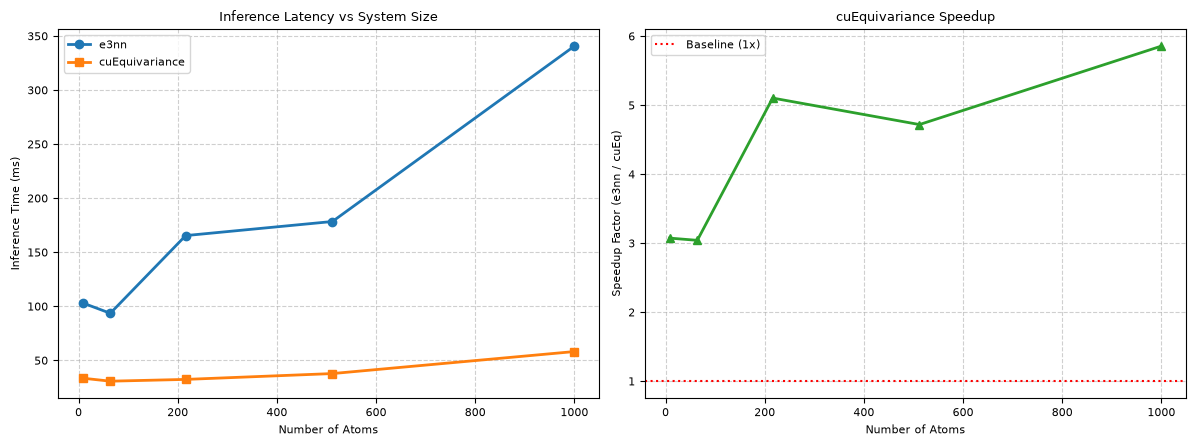

In [5]:
atom_counts = [r["atoms"] for r in results]
e3nn_times = [r["e3nn"] for r in results]
cueq_times = [r["cueq"] for r in results]
speedups = [r["speedup"] for r in results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Execution time comparison
ax1.plot(atom_counts, e3nn_times, marker="o", lw=2, label="e3nn")
ax1.plot(atom_counts, cueq_times, marker="s", lw=2, label="cuEquivariance")
ax1.set_xlabel("Number of Atoms")
ax1.set_ylabel("Inference Time (ms)")
ax1.set_title("Inference Latency vs System Size")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

# Speedup factor
ax2.plot(atom_counts, speedups, marker="^", color="tab:green", lw=2)
ax2.axhline(1.0, color="red", linestyle=":", label="Baseline (1x)")
ax2.set_xlabel("Number of Atoms")
ax2.set_ylabel("Speedup Factor (e3nn / cuEq)")
ax2.set_title("cuEquivariance Speedup")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

## 4. Molecular Dynamics (MD) Performance Comparison

Now we compare both backends in an actual ASE Molecular Dynamics simulation (NVT ensemble with the Bussi thermostat), measuring the total simulation wall time.

In [6]:
# Use the 64-atom Silicon supercell for MD
md_atoms = bulk("Si", "diamond", a=5.43, cubic=True).repeat((2, 2, 2))

def run_md_simulation(calculator, initial_atoms, steps=50, timestep_fs=1.0, temperature_K=300):
    sim_atoms = initial_atoms.copy()
    sim_atoms.calc = calculator
    sim_atoms.set_constraint([FixCom()])
    
    thermalize_momenta(sim_atoms, temperature_K=temperature_K)
    integrator = Bussi(
        atoms=sim_atoms,
        timestep=timestep_fs * ase.units.fs,
        temperature_K=temperature_K,
        taut=100.0 * ase.units.fs,
    )
    
    # Warmup 2 steps
    integrator.run(2)
    
    torch.cuda.synchronize()
    start_time = time.perf_counter()
    integrator.run(steps)
    torch.cuda.synchronize()
    
    elapsed = time.perf_counter() - start_time
    return elapsed

md_steps = 50
print(f"Running {md_steps} MD steps for bulk Si with {len(md_atoms)} atoms...")

time_md_e3nn = run_md_simulation(calc_e3nn, md_atoms, steps=md_steps)
print(f"e3nn MD elapsed time:            {time_md_e3nn:.2f} s ({time_md_e3nn / md_steps * 1000:.1f} ms/step)")

time_md_cueq = run_md_simulation(calc_cueq, md_atoms, steps=md_steps)
print(f"cuEquivariance MD elapsed time:  {time_md_cueq:.2f} s ({time_md_cueq / md_steps * 1000:.1f} ms/step)")

md_speedup = time_md_e3nn / time_md_cueq
print(f"MD Speedup with cuEquivariance:  {md_speedup:.2f}x")

Running 50 MD steps for bulk Si with 64 atoms...


/home/mvezzelli-iit.local/miniconda3/envs/test-franken/lib/python3.12/site-packages/ase/md/md.py:128: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  self.masses.shape = (-1, 1)


e3nn MD elapsed time:            1.54 s (30.7 ms/step)
cuEquivariance MD elapsed time:  1.60 s (32.1 ms/step)
MD Speedup with cuEquivariance:  0.96x


## Summary

- **Seamless switching**: Enabling cuEquivariance requires only passing `use_cueq=True` to `FrankenCalculator` or calling `model.enable_cueq()`. Fitted weights, scalers, and shifts are strictly preserved.
- **Accurate**: Force and energy predictions agree with the standard `e3nn` training backend within numerical tolerances.
- **High performance**: cuEquivariance delivers notable speedups (often 3x to 6x on medium-to-large atomic configurations), drastically accelerating long MD trajectories in production.